In [ ]:
from pathlib import Path
import sys

for _parent in (Path.cwd(), *Path.cwd().parents):
    if (_parent / "src" / "regression_module.py").exists():
        sys.path.insert(0, str(_parent / "src"))
        break


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from regression_module import load_house_data
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import StandardScaler
np.set_printoptions(precision=2)

In [2]:
# load house data
X_train, y_train = load_house_data()
X_features = ['size(sqft)', 'bedrooms', 'floors', 'age']

In [3]:
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")

X_train shape: (100, 4)
y_train shape: (100,)


In [4]:
# scale/normalize the training data
scaler = StandardScaler()
X_norm = scaler.fit_transform(X_train)

print(f"peak to peak range by column in raw: {np.ptp(X_train, axis=0)}")
print(f"peak to peak range by column in normalized: {np.ptp(X_norm, axis=0)}")

peak to peak range by column in raw: [2.41e+03 4.00e+00 1.00e+00 9.50e+01]
peak to peak range by column in normalized: [5.84 6.13 2.06 3.68]


In [5]:
# create and fit the regression model
sgdr = SGDRegressor(max_iter=1000)
sgdr.fit(X_norm, y_train)
print(sgdr)
print(f"number of iterations completed: {sgdr.n_iter_}, number of weight updates: {sgdr.t_}")

SGDRegressor()
number of iterations completed: 133, number of weight updates: 13301.0


In [6]:
# parameters
b_norm = sgdr.intercept_
w_norm = sgdr.coef_

print(f"model parameters:                              w: {w_norm}, b: {b_norm}")
print(f"model parameters from previous implementation: w: [110.56 -21.27 -32.71 -37.97], b: 363.16")

model parameters:                              w: [110.3  -21.29 -32.49 -37.85], b: [362.22]
model parameters from previous implementation: w: [110.56 -21.27 -32.71 -37.97], b: 363.16


In [9]:
# make predictions
y_pred_sgd = sgdr.predict(X_norm) # one way

y_pred = np.dot(X_norm, w_norm) + b_norm # second way

print(f"prediction using np.dot() and sgdr.predict match: {(y_pred == y_pred_sgd).all()}")

print(f"Prediction on training set: {y_pred[:4]}" )
print(f"Target values: {y_train[:4]}")

prediction using np.dot() and sgdr.predict match: True
Prediction on training set: [248.59 295.57 485.74 389.64]
Target values: [271.5 300.  509.8 394. ]


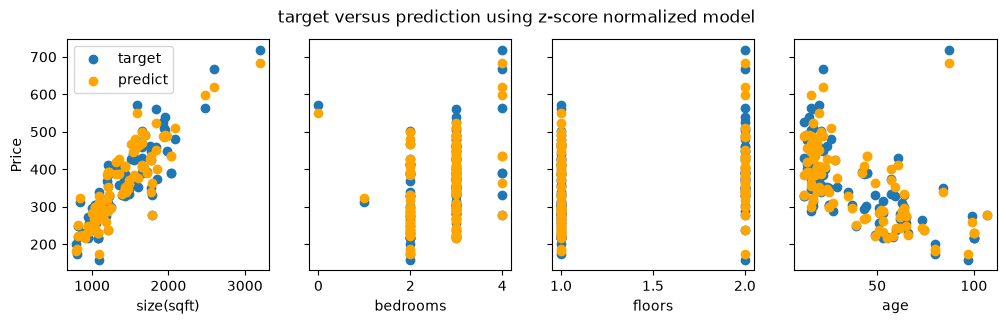

In [11]:
# plot predictions and targets vs original features    
fig,ax=plt.subplots(1,4,figsize=(12,3),sharey=True)
for i in range(len(ax)):
    ax[i].scatter(X_train[:,i],y_train, label = 'target')
    ax[i].set_xlabel(X_features[i])
    ax[i].scatter(X_train[:,i],y_pred,color="orange", label = 'predict')
ax[0].set_ylabel("Price"); ax[0].legend();
fig.suptitle("target versus prediction using z-score normalized model")
plt.show()